# Onboarding demo: from raw data to a structured and automated DataJoint pipeline

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SCENE-Collaboration/SCENE-pipelines/blob/dev/examples/tutorials/02_scene_onboarding_demo.ipynb)

This notebook covers a basic example of all the steps to onboard your lab with the SCENE DataJoint pipelines. 
Starting with raw example data, all the way to an automated DataJoint pipeline. We use the shared tables (`Session`, `VideoRecording`, `dlc.Pose`, …), and put some of the lab's own tables on top. 

**Code**

The code product of this tutorial is packaged in [`scene_onboarding_demo`](https://github.com/SCENE-Collaboration/SCENE-pipelines/tree/dev/examples/tutorials/scene_onboarding_demo), next to this
notebook. In this notebook we walk through the steps to arrive there.

If you are new to DataJoint and to the SCENE-pipelines repository, we recommend first running the [Getting started](01_getting_started.ipynb) notebook for the basics of the shared tables.


**Before you start** (on Colab, the first code cell does all of this)

- Install the package with its DeepLabCut and video extras, from the repository root:
  `pip install -e ".[dlc,video]" matplotlib`
- Start the local MySQL database: `make init` once, then `make db_up`
- Run this notebook from `examples/tutorials/`, so that `tutorial_utils` and `scene_onboarding_demo` can be
  imported

Everything is written to databases named `tutorial_onboarding_*`. Every step can run again.

In [1]:
# On Google Colab only: a local MySQL server, the package and this folder. Elsewhere this cell does nothing.
import os
import sys

SCENE_REF = "dev"  # the branch or tag of SCENE-pipelines to install

if "google.colab" in sys.modules:
    !apt-get -qq update > /dev/null && apt-get -qq install -y mysql-server > /dev/null
    !service mysql start
    !mysql -u root -e "ALTER USER 'root'@'localhost' IDENTIFIED WITH mysql_native_password BY 'tutorial'"
    !pip install -q "scene-pipelines[dlc,video] @ git+https://github.com/SCENE-Collaboration/SCENE-pipelines.git@{SCENE_REF}"
    !git clone -q --depth 1 -b {SCENE_REF} https://github.com/SCENE-Collaboration/SCENE-pipelines.git /content/SCENE-pipelines
    %cd /content/SCENE-pipelines/examples/tutorials
    os.environ["DJ_PASS"] = "tutorial"

## The data

This notebook uses basic representative example data of what your behavioral data could look like: a set of video recordings, session files (`sessions/`), and a DeepLabCut project.


The example data is one zip of about 54 MB. This cell downloads it and unpacks it into `scene_onboarding_data/`, next to this notebook; it can also be manually downloaded from the repository via [this link](https://github.com/SCENE-Collaboration/SCENE-pipelines/releases/download/tutorial-data/scene-onboarding-demo-data-v1.zip). 


- Already have the zip? Put it next to this notebook, and the cell only unpacks it.
- Stopped halfway? Delete `scene_onboarding_data/` and run the cell again.

**Layout**
```text
scene_onboarding_data/                          next to the notebook: the unpacked data zip
├── sessions/
│   ├── mice.json                               the lab's mice: name, sex, birth date, strain
│   └── <mouse>_<YYYY-MM-DD>_<attempt>/         one folder per session, named by its code
│       ├── <mouse>_<YYYY-MM-DD>_<attempt>.json  the transfer GUI's file: details + welfare
│       └── recording.json                      the tracked video: camera, video, poses, arena
├── active_sensing_ephys-celia-2026-06-26/      the DeepLabCut project, offline video and poses
└── live/                                       the live recordings, poses and frame times
```

**Acknowledgements**

The mouse *DemoTuatara* and every metadata value in the data's `sessions/` folder are made up for
this demo. The recordings and DeepLabCut results are real data from unpublished neural recordings in the AR task.
If you use this data, please cite

> Benquet, C., Sainsbury, T., Bruneau, L., et al., & Mathis, M. W. (2026). Visual uncertainty and task demands shape active sensing strategies in mice. *Current Biology*, *36*(14), 3523–3534.e9. [https://doi.org/10.1016/j.cub.2026.06.011](https://doi.org/10.1016/j.cub.2026.06.011)

In [2]:
import shutil
import urllib.request
from pathlib import Path

URL = "https://github.com/SCENE-Collaboration/SCENE-pipelines/releases/download/tutorial-data/scene-onboarding-demo-data-v1.zip"
ZIP = Path("scene-onboarding-demo-data-v1.zip")
DATA = Path("scene_onboarding_data").resolve()  # next to this notebook; change it for another copy

if not DATA.exists():
    if not ZIP.exists():
        urllib.request.urlretrieve(URL, ZIP)
    shutil.unpack_archive(ZIP, DATA)

# Print the unpacked files and directories
print("\n".join(path.name for path in DATA.iterdir()))

active_sensing_ephys-celia-2026-06-26
live
README.md
sessions


## Setup demo databases and connect

This section sets up local databases for the tutorial. Normally, this process is already taken
care of for your lab, before you start ingesting data for your experiments. Each lab has a contact person that will
set this up together with the SCENE Data Science Core.

Connecting to the central Simons server will be made easier using single sign-on.

In [3]:
import datajoint as dj
import tutorial_utils

# Connect to the DataJoint service
SCHEMA_PREFIX = "tutorial_onboarding_"
tutorial_utils.connect(prefix=SCHEMA_PREFIX)

127.0.0.1:3310, schemas prefixed 'tutorial_onboarding_'


SCENE is built from DataJoint schemas: groups of related tables, such as video, dlc and the lab's own. A lab uses only the schemas it needs. Importing a schema's module declares its tables in Python. Activating the schema then creates those tables in the database, if they don't exist yet, and binds the Python classes to them, so you can read and write through them.

This notebook uses the shared layers below, and adds the lab's own tables in step 2c. Each file on
disk ends up in one layer:

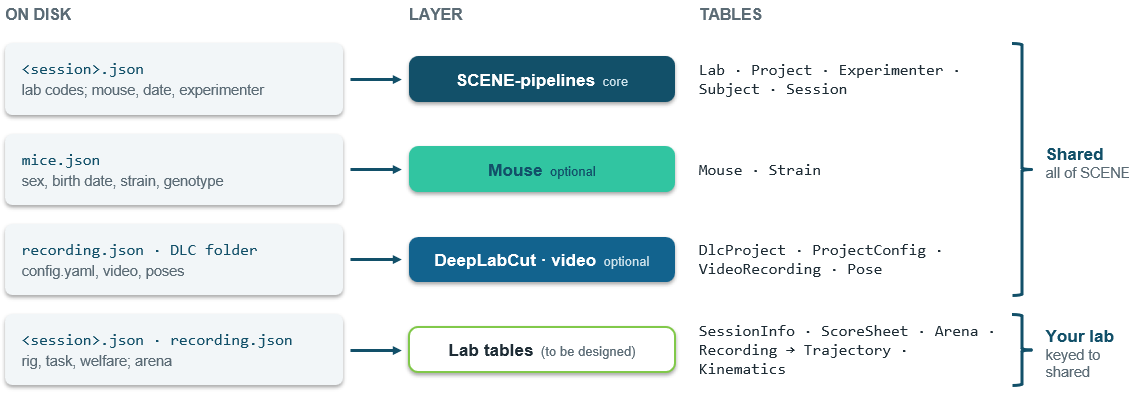

Two more shared schemas work in the background: `provenance` records which database wrote each
shared row, and `files` records each file by its hash (the bytes stay on disk).

Importing the ingestion helpers declares the shared schemas they write to; `activate_all()` then
creates their tables:

In [4]:
import scene_pipelines.ingestion.dlc  # noqa: F401
import scene_pipelines.ingestion.mouse  # noqa: F401
import scene_pipelines.ingestion.video  # noqa: F401
from scene_pipelines.core import SCENE_REGISTRY

SCENE_REGISTRY.activate_all()

[2026-11-27 10:48:39] DataJoint 2.3.6 connected to root@127.0.0.1:3310


## The lab's codes

`scene_onboarding_demo/admin.py` holds the lab's codes: the lab, its project,
and a code for each experimenter and each DeepLabCut project.

Codes in the shared tables are seen by the whole consortium, so they must not name anyone. The GUI
records an experimenter's name, and DeepLabCut names a project folder after its labeller; the lab's
code replaces both.

In [5]:
from scene_onboarding_demo import admin

print("lab:     ", admin.LAB)
print("project: ", admin.PROJECT)
print("experimenters:      ", admin.EXPERIMENTER_CODES)
print("DeepLabCut projects:", admin.DLC_PROJECT_CODES)

lab:      {'lab_id': 'demo', 'lab_name': 'DEMO lab', 'institution': 'SCENE workshop'}
project:  {'project_name': 'demo_active_sensing', 'project_title': 'DEMO: active sensing in a 52 cm open field'}
experimenters:       {'John Demo': 'E01', 'Jane Doe': 'E02', 'Jill Doe': 'E03'}
DeepLabCut projects: {'active_sensing_ephys-celia-2026-06-26': 'active-sensing-ephys'}


Once per lab, an admin registers the lab, its project, and its experimenters' codes, with the
helpers of `scene_pipelines.ingestion`:

In [6]:
from scene_pipelines.ingestion.provenance import DuplicatePolicy
from scene_pipelines.ingestion.scene.admin import ensure_lab, ensure_project
from scene_pipelines.schemas.scene.session import Experimenter

from scene_onboarding_demo.admin import EXPERIMENTER_CODES, LAB, LAB_KEY, PROJECT

ensure_lab(LAB, if_exists=DuplicatePolicy.VERIFY)
ensure_project(PROJECT, if_exists=DuplicatePolicy.VERIFY)
for code in EXPERIMENTER_CODES.values():
    Experimenter.insert1({**LAB_KEY, "experimenter_code": code}, skip_duplicates=True)

## What we build

The lab's code ends up in the package `scene_onboarding_demo`, next to this notebook. This
notebook writes it step by step, then packages it: each step below ends in one of these files.

```text
scene_onboarding_demo/
├── admin.py      the lab's codes, set once                        (done, above)
├── manifest.py   step 1: read and check a session folder
├── schemas/      steps 2c and 3: the lab's own tables
├── register.py   step 2c: write the lab's own tables
├── ingest.py     step 4: steps 1 to 3 in one call; step 5: run it on a schedule
└── plots.py      figures of a recording
```

## 1. Read and check the lab's files

The lab's data folder holds one folder per session, named by its code
(`<mouse>_<YYYY-MM-DD>_<attempt>`), and `mice.json` with the lab's mice:

In [7]:
from scene_onboarding_demo.manifest import discover_sessions

sessions = discover_sessions(DATA / "sessions")
for folder in sessions:
    print(folder.name)

FIRST, SECOND = sessions

DemoTuatara_2026-06-26_1
DemoTuatara_2026-11-03_1


A session folder has two small files: the transfer GUI's file, with the session's details and
welfare check, and `recording.json`, which says where the video and the poses are. As they are on
disk:

In [8]:
from scene_onboarding_demo.manifest import gui_file, read_json

display(read_json(DATA / "sessions" / "mice.json"))
display(read_json(gui_file(FIRST)))
read_json(FIRST / "recording.json")

[{'mouse_name': 'DemoTuatara',
  'sex': 'F',
  'date_of_birth': '2026-03-12',
  'strain': 'C57BL/6J',
  'genotype': 'wt'}]

{'mouse_name': 'DemoTuatara',
 'doe': '2026-06-26',
 'attempt': 1,
 'experimenter_name': 'John Demo',
 'rig_id': 2,
 'task_name': 'active_sensing_ephys',
 'anesthesia_name': 'awake',
 'opto_name': 'none',
 'session_notes': 'DEMO: made-up metadata for the SCENE workshop. Offline DeepLabCut analysis of the first 30 s.',
 'license': 'N/A',
 'body_condition': 'BodyCondition3',
 'general_assay': 'Assay5',
 'housing_assay': 'Yes',
 'weight_percentage': '-2.5'}

{'session_code': 'DemoTuatara_2026-06-26_1',
 'camera': 'top',
 'take': 1,
 'dlc_project': 'active_sensing_ephys-celia-2026-06-26',
 'video': 'active_sensing_ephys-celia-2026-06-26/videos/active_sensing_ephys_first_30s.avi',
 'poses': 'active_sensing_ephys-celia-2026-06-26/videos/active_sensing_ephys_first_30sDLC_Resnet50_active_sensing_ephysJun26shuffle8_snapshot_best-100.h5',
 'frame_times': None,
 'arena': {'arena_name': 'openfield_52',
  'width_cm': 52,
  'depth_cm': 52,
  'corners_px': [[27.5, 36.7], [496.3, 25.4], [502.8, 507.8], [26.9, 491.5]]}}

Before anything is written, each file is read into a model that checks it: one
[pydantic](https://docs.pydantic.dev) class per file, with a type for every field. Unknown fields
are errors. The GUI's file, for example:

In [9]:
from tutorial_utils import display_code

from scene_onboarding_demo.manifest import SessionEntry

display_code(SessionEntry)

```python
class SessionEntry(Entry):
    """The transfer GUI's file of one session (the MouseAR format)."""

    mouse_name: str
    session_date: date = Field(alias="doe")  # the GUI calls it 'doe', date of experiment
    attempt: int = Field(ge=1)
    experimenter_name: str
    rig_id: int
    task_name: str
    anesthesia_name: str = "awake"
    opto_name: str = "none"
    session_notes: str = ""
    # the welfare check, done at the session
    license: str
    body_condition: str
    general_assay: str
    housing_assay: str
    weight_percentage: float

    @property
    def session_code(self) -> str:
        return f"{self.mouse_name}_{self.session_date}_{self.attempt}"

```

`read_session_folder` reads a whole folder (the mouse, the session and the recording) and checks
that they agree:

In [10]:
import pandas as pd

from scene_onboarding_demo.manifest import read_session_folder

manifest = read_session_folder(FIRST)
pd.Series(manifest.session.model_dump(), name=manifest.session.session_code).to_frame()

,DemoTuatara_2026-06-26_1
mouse_name,DemoTuatara
session_date,2026-06-26
attempt,1
experimenter_name,John Demo
rig_id,2
task_name,active_sensing_ephys
anesthesia_name,awake
opto_name,none
session_notes,DEMO: made-up metadata for the SCENE workshop....
license,N/A


A wrong field fails here, by name, and nothing is written:

In [11]:
from pydantic import ValidationError

broken = {**read_json(gui_file(FIRST)), "weight_percentage": "heavy", "rig": 2}
try:
    SessionEntry(**broken)
except ValidationError as error:
    print(error)

2 validation errors for SessionEntry
weight_percentage
  Input should be a valid number, unable to parse string as a number [type=float_parsing, input_value='heavy', input_type=str]
    For further information visit https://errors.pydantic.dev/2.13/v/float_parsing
rig
  Extra inputs are not permitted [type=extra_forbidden, input_value=2, input_type=int]
    For further information visit https://errors.pydantic.dev/2.13/v/extra_forbidden


→ This is [`manifest.py`](https://github.com/SCENE-Collaboration/SCENE-pipelines/blob/dev/examples/tutorials/scene_onboarding_demo/manifest.py).

## 2. Register in the database

Each field goes either to a shared table, seen by the whole consortium, or to one of the lab's
own tables. Names of people are replaced by the lab's codes.

| From | Field | To | Layer |
|---|---|---|---|
| `mice.json` | `mouse_name`, `sex`, `date_of_birth`, `strain`, `genotype` | `Subject`, `Mouse`, `Strain` | shared |
| GUI file | `mouse_name`, `doe`, `attempt` | `Session` (`session_code`, `session_date`) | shared |
| GUI file | `experimenter_name` | `Session.experimenter_code`, via `EXPERIMENTER_CODES`; the name is not stored | shared |
| GUI file | `attempt`, `rig_id`, `task_name`, `anesthesia_name`, `opto_name`, `session_notes` | `SessionInfo` | lab |
| GUI file | `license`, `body_condition`, `general_assay`, `housing_assay`, `weight_percentage` | `ScoreSheet` | lab |
| `recording.json` | `dlc_project` | `dlc.DlcProject` (via `DLC_PROJECT_CODES`), `dlc.ProjectConfig` | shared |
| `recording.json` | `video`, `take`, `video_timestamps` | `video.VideoRecording`, `video.VideoFile` | shared |
| `recording.json` | `poses`, `frame_times` | `dlc.Pose` | shared |
| `recording.json` | `arena`, the video's path | `Arena`, `Recording` | lab |
| `recording.json` | `camera` | not stored: the lab's own name | |

### 2a. Shared, once per mouse and DeepLabCut project

The mouse, and the DeepLabCut project: `DlcProject` under the lab's code, and `ProjectConfig`, one
row per version of its `config.yaml`, with the keypoints and the likelihood threshold (`pcutoff`).
The file itself is not uploaded: SCENE records its hash. All are written with the helpers of
`scene_pipelines.ingestion`.

The project's labelled frames (`CollectedData_*.h5`) are not in the shared schema yet, so this
version of the demo does not register them.

In [12]:
from scene_pipelines.ingestion.dlc import register_dlc_project, register_project_config
from scene_pipelines.ingestion.mouse import ensure_strain, register_mouse
from scene_pipelines.schemas.dlc.project import DlcProject, ProjectConfig
from scene_pipelines.schemas.mouse.mouse import Mouse
from scene_pipelines.schemas.scene.subject import Subject

from scene_onboarding_demo.admin import DLC_PROJECT_CODES, PROJECT_KEY

mouse = register_mouse(
    manifest.mouse.mouse_name,
    manifest.mouse.sex,
    lab=LAB_KEY,
    date_of_birth=manifest.mouse.date_of_birth,
    strain=ensure_strain({"strain_name": manifest.mouse.strain}),
    genotype=manifest.mouse.genotype or None,
)

rec = manifest.recording
project = register_dlc_project(
    DLC_PROJECT_CODES[rec.dlc_project.name], lab=LAB_KEY, scene_project=PROJECT_KEY
)
config = register_project_config(DATA / rec.dlc_project / "config.yaml", dlc_project=project)

display((Subject * Mouse & mouse).proj("subject_code", "sex", "date_of_birth", "strain_name"))
display(DlcProject & project)
(ProjectConfig & config).proj("task", "pcutoff") * ProjectConfig.Bodypart

subject_id,subject_code,sex,date_of_birth,strain_name
3e5c59e8-d5ed-461a-8306-f2c9f5f9f2b1,DemoTuatara,F,2026-03-12,C57BL/6J


lab_id,dlc_project_id,dlc_project_code,project_name
demo,95eceec1-ed83-46a2-9225-7ab8a88d4c67,active-sensing-ephys,demo_active_sensing


lab_id,dlc_project_id,file_sha256,bodypart_index,bodypart,task,pcutoff
demo,95eceec1-ed83-46a2-9225-7ab8a88d4c67,7d6b4455d38e1a39c00dd41b8c123abd7503843d5d694624a78d00a1207ef0be,0,nose,active_sensing_ephys,0.6
demo,95eceec1-ed83-46a2-9225-7ab8a88d4c67,7d6b4455d38e1a39c00dd41b8c123abd7503843d5d694624a78d00a1207ef0be,1,left_ear,active_sensing_ephys,0.6
demo,95eceec1-ed83-46a2-9225-7ab8a88d4c67,7d6b4455d38e1a39c00dd41b8c123abd7503843d5d694624a78d00a1207ef0be,2,right_ear,active_sensing_ephys,0.6
demo,95eceec1-ed83-46a2-9225-7ab8a88d4c67,7d6b4455d38e1a39c00dd41b8c123abd7503843d5d694624a78d00a1207ef0be,3,left_ear_tip,active_sensing_ephys,0.6
demo,95eceec1-ed83-46a2-9225-7ab8a88d4c67,7d6b4455d38e1a39c00dd41b8c123abd7503843d5d694624a78d00a1207ef0be,4,right_ear_tip,active_sensing_ephys,0.6
demo,95eceec1-ed83-46a2-9225-7ab8a88d4c67,7d6b4455d38e1a39c00dd41b8c123abd7503843d5d694624a78d00a1207ef0be,5,left_eye,active_sensing_ephys,0.6
demo,95eceec1-ed83-46a2-9225-7ab8a88d4c67,7d6b4455d38e1a39c00dd41b8c123abd7503843d5d694624a78d00a1207ef0be,6,right_eye,active_sensing_ephys,0.6
demo,95eceec1-ed83-46a2-9225-7ab8a88d4c67,7d6b4455d38e1a39c00dd41b8c123abd7503843d5d694624a78d00a1207ef0be,7,neck,active_sensing_ephys,0.6
demo,95eceec1-ed83-46a2-9225-7ab8a88d4c67,7d6b4455d38e1a39c00dd41b8c123abd7503843d5d694624a78d00a1207ef0be,8,mid_back,active_sensing_ephys,0.6
demo,95eceec1-ed83-46a2-9225-7ab8a88d4c67,7d6b4455d38e1a39c00dd41b8c123abd7503843d5d694624a78d00a1207ef0be,9,mouse_center,active_sensing_ephys,0.6


### 2b. Shared, per session: the session, its video and the video's poses

The session, with its mouse, project and experimenter's code. The video goes to
`video.VideoRecording` (its take, and the video's fps, size and frame count), and its DeepLabCut
poses to `dlc.Pose`, one row per keypoint in `Pose.Keypoint`. This first session has no frame
times; for the live session in step 4, `ingest` also passes the recorder's and DLC-live's.

In [13]:
from scene_pipelines.ingestion import register_session
from scene_pipelines.ingestion.dlc import register_pose
from scene_pipelines.ingestion.video import register_video_recording
from scene_pipelines.schemas.dlc.pose import Pose
from scene_pipelines.schemas.scene.session import Session
from scene_pipelines.schemas.video.recording import VideoRecording
from scene_pipelines.schemas.video.video import VideoFile

from scene_onboarding_demo.admin import EXPERIMENTER_CODES

session = register_session(
    manifest.session.session_code,
    manifest.session.session_date,
    lab=LAB_KEY,
    subjects=[mouse],
    project=PROJECT_KEY,
    experimenter={
        **LAB_KEY,
        "experimenter_code": EXPERIMENTER_CODES[manifest.session.experimenter_name],
    },
)
video = register_video_recording(DATA / rec.video, session=session, take=rec.take)
pose = register_pose(
    DATA / rec.poses,
    dlc_project=project,
    video={"file_sha256": (VideoRecording & video).fetch1("file_sha256")},
)

display(Session & session)
display((VideoRecording * VideoFile & video).proj("fps", "width", "height", "n_frames"))
Pose & pose

session_id,lab_id,session_code,session_date,project_name,experimenter_code
a6a0daa1-1a8c-44f8-8f1a-b21848834a77,demo,DemoTuatara_2026-06-26_1,2026-06-26,demo_active_sensing,E01


session_id,take,fps,width,height,n_frames
a6a0daa1-1a8c-44f8-8f1a-b21848834a77,1,100.0,530,510,3000


pose_id,file_sha256,scorer,n_frames,frame_index,frame_time
344534c2-c659-5e23-9b93-c412f70912b1,733ba7f438fb9769f95681f01430f686442005aab745de75be183f29ed0c73de,DLC_Resnet50_active_sensing_ephysJun26shuffle8_snapshot_best-100,3000,<blob>,<blob>


### 2c. The lab's own tables

What only this lab records goes to its own tables, on top of the shared rows. They are in
[`schemas/`](https://github.com/SCENE-Collaboration/SCENE-pipelines/tree/dev/examples/tutorials/scene_onboarding_demo/schemas): `SessionInfo` and `ScoreSheet` for the session's
details and welfare check, and `Recording`, which ties the shared video to its poses and adds the
arena and where its corners are in the image. They reference the shared tables; nothing in
scene-pipelines changes.

```text
Session ─> VideoRecording ─┐
dlc.Pose ──────────────────┼──> Recording ──> Trajectory ──> Kinematics
dlc.ProjectConfig, Arena ──┘    (Manual)      (Computed)     (Computed)
```

In [14]:
from scene_onboarding_demo.schemas import Recording, ScoreSheet, SessionInfo

display_code(Recording)

```python
@schema
class Recording(dj.Manual):
    definition = """
    # a tracked video of a session, with its arena; from recording.json
    -> VideoRecording
    ---
    -> Pose                                              # the poses the lab analyses
    -> ProjectConfig.proj(config_sha256='file_sha256')   # the DeepLabCut config: its pcutoff
    -> Arena
    corners_px: <blob>                   # (4, 2) arena floor corners, clockwise from top-left
    video_path: varchar(1024)            # relative to the data folder; not uploaded
    """

    def pose(self, key) -> dict:
        """The ``Pose`` key of a recording."""
        return {"pose_id": (self & key).fetch1("pose_id")}

    def pcutoff(self, key) -> float:
        """The likelihood threshold of the config that tracked the recording."""
        config = ProjectConfig.proj("pcutoff", config_sha256="file_sha256")
        recording = (self & key).proj("dlc_project_id", "config_sha256")
        return float((recording * config).fetch1("pcutoff"))

    def times(self, key) -> np.ndarray:
        """Seconds of each pose from the first: DLC-live's times, else frame number / fps."""
        n_frames, frame_time = (Pose & self.pose(key)).fetch1("n_frames", "frame_time")
        if frame_time is not None:
            return frame_time - frame_time[0]
        fps = (VideoRecording * VideoFile & key).fetch1("fps")
        return np.arange(n_frames) / fps

    def pixels_to_cm(self, key) -> np.ndarray:
        """The (3, 3) perspective transform from image pixels to arena centimetres."""
        corners, width, depth = (self * Arena & key).fetch1("corners_px", "width_cm", "depth_cm")
        arena = np.float32([[0, 0], [width, 0], [width, depth], [0, depth]])
        return cv2.getPerspectiveTransform(np.float32(corners), arena)

```

Importing `scene_onboarding_demo.schemas` declared the lab's two schemas, `lab` and `behavior`, in
Python. Activating them creates their tables in the database, next to the shared ones. That
includes `Trajectory` and `Kinematics`, the computed tables of step 3. Shared schemas that are
active already are left as they are.

In [15]:
SCENE_REGISTRY.activate_all()

Two small helpers write them:

In [16]:
from scene_onboarding_demo.register import register_recording, register_session_details

display_code(register_session_details)
display_code(register_recording)

```python
def register_recording(entry: RecordingEntry, *, video: dict, pose: dict, config: dict) -> dict:
    """The lab's ``Recording``: a shared video and its poses, with the lab's arena.

    Returns:
        The ``Recording`` key: the video's.
    """
    Arena.insert1(entry.arena.model_dump(exclude={"corners_px"}), skip_duplicates=True)
    Recording.insert1(
        {
            **video,
            **pose,
            "lab_id": config["lab_id"],
            "dlc_project_id": config["dlc_project_id"],
            "config_sha256": config["file_sha256"],
            "arena_name": entry.arena.arena_name,
            "corners_px": np.array(entry.arena.corners_px),
            "video_path": entry.video.as_posix(),
        },
        skip_duplicates=True,
    )
    return video

```

In [17]:
register_session_details(manifest.session, session=session)
recording = register_recording(rec, video=video, pose=pose, config=config)

display(SessionInfo * ScoreSheet & session)
(Recording & recording).proj("arena_name", "video_path")

session_id,attempt,rig_id,task_name,anesthesia_name,opto_name,session_notes,license,body_condition,general_assay,housing_assay,weight_percentage
a6a0daa1-1a8c-44f8-8f1a-b21848834a77,1,2,active_sensing_ephys,awake,none,DEMO: made-up metadata for the SCENE workshop. Offline DeepLabCut analysis of the first 30 s.,N/A,BodyCondition3,Assay5,Yes,-2.5


session_id,take,arena_name,video_path
a6a0daa1-1a8c-44f8-8f1a-b21848834a77,1,openfield_52,active_sensing_ephys-celia-2026-06-26/videos/active_sensing_ephys_first_30s.avi


→ This is [`schemas/`](https://github.com/SCENE-Collaboration/SCENE-pipelines/tree/dev/examples/tutorials/scene_onboarding_demo/schemas) and [`register.py`](https://github.com/SCENE-Collaboration/SCENE-pipelines/blob/dev/examples/tutorials/scene_onboarding_demo/register.py).

## 3. Computed for you

`Trajectory` and `Kinematics` are computed tables. Each has a `definition` (what is stored per
key) and a `make(key)` that reads its upstream rows and inserts one row. That pair is all
`populate()` needs to fill exactly what is missing, for this session or the next hundred.
`Trajectory.make` reads the poses back with `scene_pipelines.ingestion.dlc.keypoint`, one keypoint
at a time. `Kinematics` sums a trajectory up:

In [18]:
from scene_onboarding_demo.schemas import Kinematics, Trajectory

display_code(Kinematics)

```python
@schema
class Kinematics(dj.Computed):
    definition = """
    # summary of a trajectory
    -> Trajectory
    ---
    duration_s: float32
    distance_cm: float32
    mean_speed_cm_s: float32             # over tracked frames
    moving_fraction: float32             # of tracked frames, faster than MOVING_CM_S
    center_fraction: float32             # of tracked frames, in the central quarter of the arena
    """

    def make(self, key):
        t = Recording().times(key)
        x, y, speed = (Trajectory & key).fetch1("x_cm", "y_cm", "speed_cm_s")
        width, depth = (Recording * Arena & key).fetch1("width_cm", "depth_cm")
        tracked = ~np.isnan(x)
        central = (np.abs(x - width / 2) < width / 4) & (np.abs(y - depth / 2) < depth / 4)
        self.insert1(
            {
                **key,
                "duration_s": float(t[-1] - t[0]),
                "distance_cm": float(np.nansum(np.hypot(np.diff(x), np.diff(y)))),
                "mean_speed_cm_s": float(np.nanmean(speed)),
                "moving_fraction": float(np.mean(speed[tracked] > MOVING_CM_S)),
                "center_fraction": float(np.mean(central[tracked])),
            }
        )

```

In [19]:
Trajectory.populate()
Kinematics.populate()

Kinematics & recording

session_id,take,duration_s,distance_cm,mean_speed_cm_s,moving_fraction,center_fraction
a6a0daa1-1a8c-44f8-8f1a-b21848834a77,1,29.99,294.75,9.68727,0.489,0.598333


The path from the `Trajectory` table, on a video frame warped to a top-down view of the 52 × 52 cm arena;
the dashed square is its central quarter.

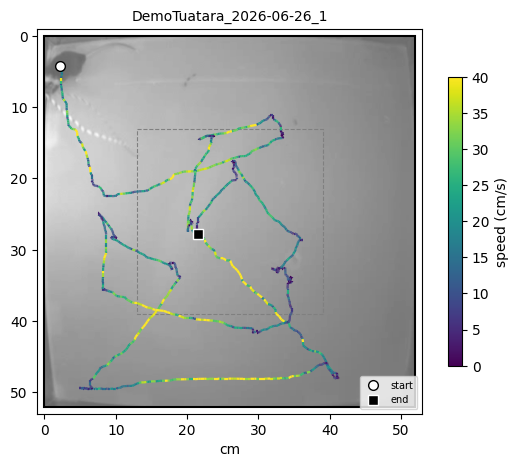

In [20]:
%matplotlib inline
import matplotlib.pyplot as plt

from scene_onboarding_demo.plots import plot_path

fig, ax = plt.subplots(figsize=(6.5, 5))
plot_path(ax, recording, data=DATA)
ax.set_title(manifest.session.session_code, fontsize=10);

---
## 4. Putting it together: `ingest()`

Steps 1 to 3, in one function in [`ingest.py`](https://github.com/SCENE-Collaboration/SCENE-pipelines/blob/dev/examples/tutorials/scene_onboarding_demo/ingest.py). The comments
number the same steps. One thing is added: the session's rows are written in one transaction, so
a session is in the database whole, or not at all.

In [21]:
from scene_onboarding_demo.ingest import ingest

display_code(ingest)

```python
def ingest(folder: Path) -> dict:
    """Read and validate a session folder, register it, compute what is missing. Safe to rerun."""
    # 1. Read and check the lab's files
    manifest = read_session_folder(folder)
    mouse, details, rec = manifest.mouse, manifest.session, manifest.recording

    # 2a. Shared, once per mouse and DeepLabCut project: recognised when they are in already
    subject = register_mouse(
        mouse.mouse_name,
        mouse.sex,
        lab=LAB_KEY,
        date_of_birth=mouse.date_of_birth,
        strain=ensure_strain({"strain_name": mouse.strain}),
        genotype=mouse.genotype or None,
    )
    project = register_dlc_project(
        DLC_PROJECT_CODES[rec.dlc_project.name], lab=LAB_KEY, scene_project=PROJECT_KEY
    )
    config = register_project_config(
        rec.data / rec.dlc_project / "config.yaml", dlc_project=project
    )

    start_time, timestamps = None, None
    if rec.video_timestamps is not None:
        start_time, timestamps = read_video_timestamps(rec.data / rec.video_timestamps)

    with atomic(Session.connection):  # the session's rows (2b and 2c): all, or none
        # 2b. Shared, per session: the session, its video and the video's poses
        session = register_session(
            details.session_code,
            details.session_date,
            lab=LAB_KEY,
            subjects=[subject],
            project=PROJECT_KEY,
            experimenter={
                **LAB_KEY,
                "experimenter_code": EXPERIMENTER_CODES[details.experimenter_name],
            },
        )
        video = register_video_recording(
            rec.data / rec.video,
            session=session,
            take=rec.take,
            frame_timestamps=timestamps,
            start_time=start_time,
        )
        pose = register_pose(
            rec.data / rec.poses,
            dlc_project=project,
            video={"file_sha256": (VideoRecording & video).fetch1("file_sha256")},
            frame_times=rec.data / rec.frame_times if rec.frame_times else None,
        )

        # 2c. The lab's own tables, on top of the shared rows
        register_session_details(details, session=session)
        register_recording(rec, video=video, pose=pose, config=config)

    # 3. Compute downstream analyses automatically
    Trajectory.populate()
    Kinematics.populate()
    return session

```

Months later the same mouse is tracked live with DeepLabCut-live. Everything the steps above did
by hand, `ingest` does for its folder. The mouse and the DeepLabCut project are recognised, not
written again.

In [22]:
ingest(SECOND)

{'session_id': UUID('e906c1b3-1236-44ce-92e7-4595f3440c96')}

Every step can run again: a second call recognises what is stored, and writes nothing twice.

In [23]:
ingest(SECOND)
print(len(Session()), "sessions,", len(Recording()), "recordings")

2

sessions,

2

recordings

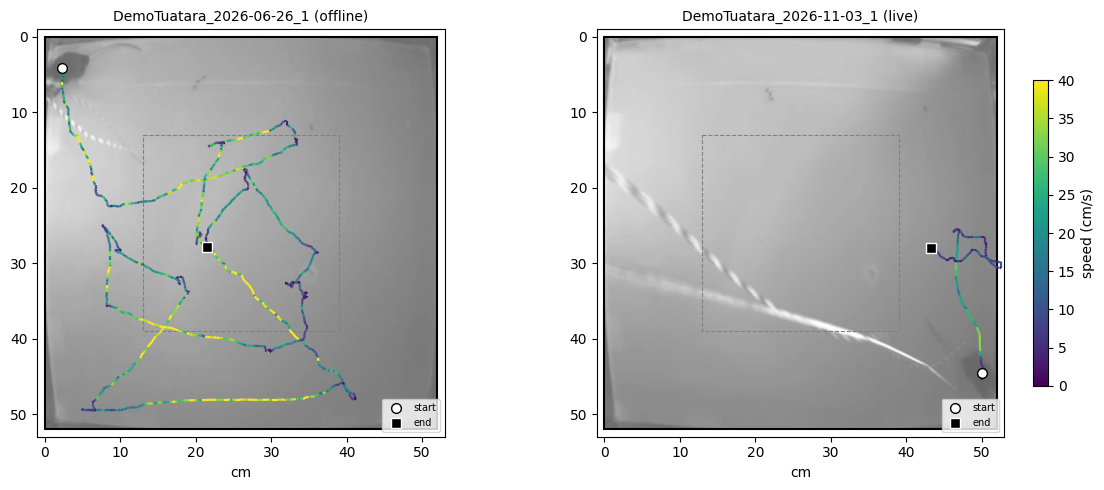

In [24]:
keys = (Recording * Session).keys(order_by="session_date")
fig, axes = plt.subplots(1, len(keys), figsize=(6 * len(keys), 5))
for ax, key in zip(axes, keys):
    plot_path(ax, key, data=DATA, colorbar=ax is axes[-1])
    session_code = (Session & key).fetch1("session_code")
    scorer = (Pose & Recording().pose(key)).fetch1("scorer")
    ax.set_title(f"{session_code} ({'live' if scorer == 'DLC_live' else 'offline'})", fontsize=10)
fig.tight_layout()

Anyone with access to the database gets the same from a query, without the lab's disks: per session, the
mouse's age, its weight change at the welfare check, and how it explored. (The live session lasts 7 s
against 30 s offline, so compare with care.)

In [25]:
per_session = (
    Session * Session.Subject * Subject * Mouse * ScoreSheet * Recording * Kinematics
).proj(
    "subject_code",
    "session_date",
    "weight_percentage",
    "distance_cm",
    "mean_speed_cm_s",
    "center_fraction",
    age_days="DATEDIFF(session_date, date_of_birth)",
)
columns = [
    "subject_code",
    "age_days",
    "session_date",
    "weight_percentage",
    "distance_cm",
    "mean_speed_cm_s",
    "center_fraction",
]
per_session.to_pandas().reset_index()[columns].round(2)

,subject_code,age_days,session_date,weight_percentage,distance_cm,mean_speed_cm_s,center_fraction
0,DemoTuatara,106,2026-06-26,-2.5,294.75,9.69,0.6
1,DemoTuatara,236,2026-11-03,1.0,46.50,6.78,0.0


## 5. Run it on a schedule

`ingest_all` ingests every session folder that is not in the database yet, and skips the rest. The
same module runs from the command line, so cron (or a script that runs after each data transfer)
can call it:

```bash
cd examples/tutorials
python -m scene_onboarding_demo.ingest /path/to/data/sessions
```

The connection comes from the environment (`DJ_HOST`, `DJ_USER`, `DJ_PASS`, `DJ_SCHEMA_PREFIX`,
`SCENE_DEPLOYMENT_ID`). A folder that fails is logged and the others go on; the exit code is then 1.
Here both sessions are in already, so nothing is written:

In [26]:
from scene_onboarding_demo.ingest import ingest_all

ingest_all(DATA / "sessions")  # the folders that failed

[]

## Start over

Drops every table under this notebook's prefix; restart the kernel afterwards. Uncomment to run.

In [27]:
from tutorial_utils import drop_tutorial_schemas

# drop_tutorial_schemas(SCHEMA_PREFIX)